# 11 · Học biểu diễn đồ thị và xếp hạng ca nên xem trước (Chương 6)

## 1. Mục tiêu và buổi học áp dụng

Bổ sung cho **câu hỏi quản trị 3** (*lệch ở đâu?*) bằng một danh sách **ca nên xem trước**, và đánh giá giá trị của biểu diễn đồ thị. Áp dụng **Buổi 6 — Node2Vec/Graph2Vec**: tái sử dụng embedding Node2Vec của giai đoạn 1 (không fit lại) và so với đặc trưng cấu trúc của Buổi 3 trên cùng một bài toán.

## 2. Đầu vào

Run `outputs/process/<run>` (bước E: `e_ranking/`). Embedding lấy từ run V1 qua `open_run` (kiểm fingerprint); điểm M_markov out-of-fold lấy từ run cải tiến (sha256 ghi trong `status.json`).

In [1]:
# Mở run giai đoạn 2 đã kiểm fingerprint. Không cần biến môi trường: nếu không chỉ định, tự chọn run
# hoàn tất mới nhất khớp configs/process.yaml hiện tại (bộ chạy `jira-ad notebooks` đặt JIRA_AD_PROCESS_RUN_DIR).
import pandas as pd
from IPython.display import Markdown, display

from jira_ad import process_plots as pp
from jira_ad.process_analysis import fmt, open_process_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 100
run = open_process_run()
print(run.header())

run: outputs/process/20261026T025412Z-399b0a40
chọn run: biến môi trường JIRA_AD_PROCESS_RUN_DIR
config: configs/process.yaml
config_hash: 399b0a40534a3d08466aaaf32175a68cb6d59cf4d90af65301ebb04c5e572a22
code.sha256: ed83115da72a96af6ecac17610d370d96a617635e4abc0c807ee7459ba84e9b6
tạo lúc (UTC): 2026-10-26T02:54:12.298067+00:00
số artifact đã kiểm sha256: 93


In [2]:
display(pd.Series(run.json("e_ranking/status.json"), name="nguồn").to_frame())
rk = run.manifest["config"]["ranking"]
display(pd.Series({k: v for k, v in rk.items() if k != "activity_groups"}, name="tham số khóa trước").to_frame())

,nguồn
representation,"đã dùng embedding của outputs/runs/20261017T081309Z-930f8a85 (đã kiểm fingerprint, không fit lại)"
markov,điểm out-of-fold M_markov từ outputs/improvement/20261022T151529Z-bb0fee9a (sha256 98b34f56ff56e...
replay,có


,tham số khóa trước
oof_method,M_markov
k_min,2
k_max,6
seed,20261026
top_share,0.100
peer_percentile,0.900
length_bins,3
n_boot,200
consensus_share,0.700
blind_top,15


## 3. Dữ liệu và giả định

- **Nhóm nghiệp vụ của activity** (trạng thái, mã nguồn, giao việc, kế hoạch, liên kết, tài liệu, phân loại) do tác giả định nghĩa trước theo loại trường Jira; đây là "nhãn" của bài toán so sánh biểu diễn, không phải sự thật khách quan.
- **Hồ sơ bất thường nhiều chiều** mỗi ca: lệch mô hình chuẩn (1 − fitness), số cờ quy tắc (không tính cờ bù), số lượt trễ định mức, lùi/mở lại, đổi người phụ trách, số lần đổi trạng thái bù, độ bất ngờ M_markov **đã khử độ dài**. Mỗi chiều đổi thành phân vị **trong nhóm cùng nhánh (DONE/Rejected) × độ dài**; xếp theo số chiều vượt p90.
- **"Điểm cao" = "nên xem trước", không phải "vi phạm"**; `Rejected` không phải bất thường; không có nhãn bất thường thật nên không có độ chính xác — chỉ có độ ổn định và tương quan.

## 4. Kết quả

### 4.1 Node2Vec so với bậc + trung tâm: tìm lại nhóm nghiệp vụ của activity

,số activity
group,
planning,12
status,10
classification,8
documentation,7
linking,6
assignment,3
code,2
other,1


,representation,n_nodes,accuracy,macro_f1
0,node2vec_v1,49,0.449,0.352
1,structural,49,0.286,0.205
2,majority_baseline,49,0.245,0.049


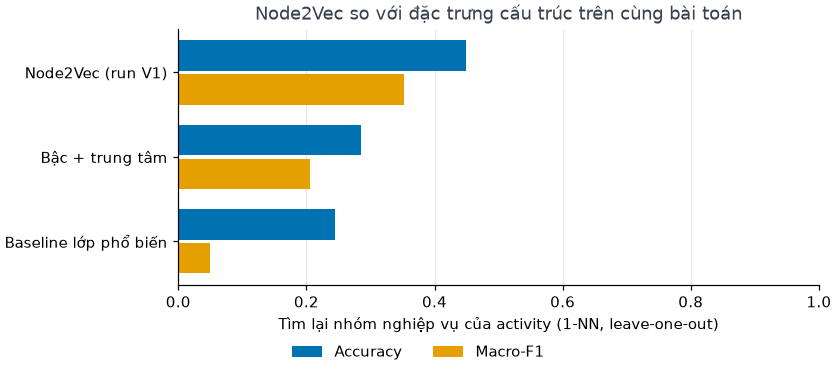

,k,silhouette,ari,nmi,representation
0,2,0.137,0.027,0.087,node2vec_v1
1,3,0.085,0.134,0.290,node2vec_v1
2,4,0.078,0.077,0.275,node2vec_v1
3,5,0.088,0.120,0.355,node2vec_v1
4,6,0.103,0.129,0.388,node2vec_v1
5,2,0.514,0.021,0.089,structural
6,3,0.517,0.034,0.178,structural
7,4,0.450,0.028,0.190,structural
8,5,0.416,0.042,0.261,structural
9,6,0.459,0.035,0.244,structural


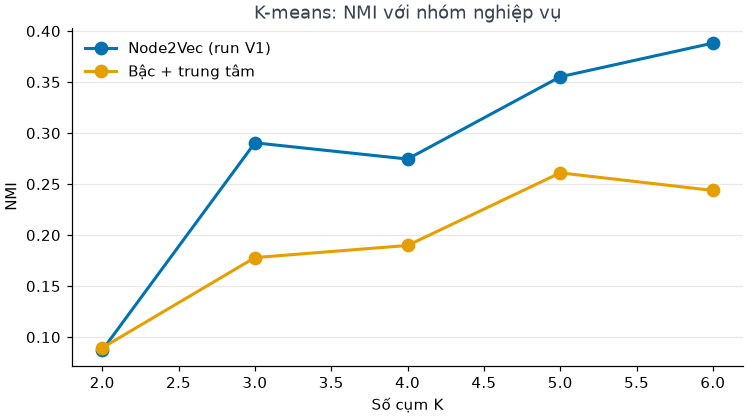

In [3]:
display(run.csv("e_ranking/groups.csv").group.value_counts().rename("số activity").to_frame())
if run.path("e_ranking/classify.csv").is_file():
    classify = run.csv("e_ranking/classify.csv")
    display(classify)
    _ = run.show(pp.plot_representation_compare(classify))
    clusters = run.csv("e_ranking/clusters.csv")
    display(clusters)
    _ = run.show(pp.plot_cluster_scan(clusters, metric="nmi"))

### 4.2 Hồ sơ bất thường và bảng xếp hạng

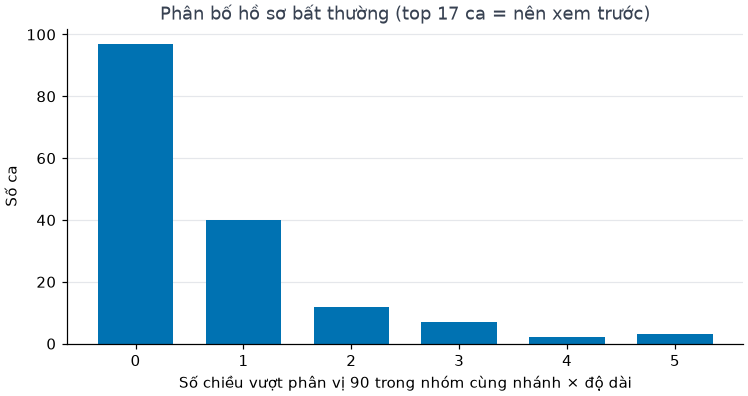

**Danh sách đồng thuận: 10 ca nằm trong top 10% ở >= 70% số lần bootstrap mà ca được rút (nên xem trước, không phải vi phạm)**

,case_id,share_top,rank,terminal_status,n_events,n_exceed,reasons
0,bug:TI-4584,1.000,3,DONE,51,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 98 trong nhóm DONE·dài); số cờ quy tắc = 3 (ph..."
1,bug:TI-4671,1.000,1,Rejected,9,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 95 trong nhóm Rejected·ngắn); số cờ quy tắc = ..."
2,bug:TI-4748,1.000,6,DONE,51,3,lùi trạng thái/mở lại = 2 (phân vị 97 trong nhóm DONE·dài); đổi người phụ trách = 7 (phân vị 100...
3,bug:TI-5260,1.000,2,Rejected,14,5,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 100 trong nhóm Rejected·vừa); số cờ quy tắc = ..."
4,bug:TI-5564,1.000,7,DONE,37,3,số cờ quy tắc = 4 (phân vị 100 trong nhóm DONE·dài); lùi trạng thái/mở lại = 2 (phân vị 97 trong...
5,bug:TI-4872,0.978,5,Rejected,8,4,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 95 trong nhóm Rejected·ngắn); số cờ quy tắc = ..."
6,bug:TI-5770,0.931,9,DONE,19,3,"lệch mô hình chuẩn (1 − fitness) = 0,125 (phân vị 94 trong nhóm DONE·vừa); số cờ quy tắc = 2 (ph..."
7,bug:TI-6208,0.881,11,DONE,20,3,"lệch mô hình chuẩn (1 − fitness) = 0,154 (phân vị 100 trong nhóm DONE·vừa); lùi trạng thái/mở lạ..."
8,bug:TI-5261,0.880,15,Rejected,12,2,"lệch mô hình chuẩn (1 − fitness) = 0,167 (phân vị 99 trong nhóm Rejected·ngắn); độ bất ngờ M_mar..."
9,bug:TI-6163,0.876,14,DONE,19,2,lùi trạng thái/mở lại = 2 (phân vị 100 trong nhóm DONE·vừa); độ bất ngờ M_markov (khử độ dài) = ...


Bảng xếp hạng đầy đủ (chỉ để tham khảo; top-k đơn lẻ không ổn định, xem 4.3)

,rank,case_id,terminal_status,n_events,peer_group,n_exceed
0,1,bug:TI-4671,Rejected,9,Rejected·ngắn,5
1,2,bug:TI-5260,Rejected,14,Rejected·vừa,5
2,3,bug:TI-4584,DONE,51,DONE·dài,5
3,4,bug:TI-5598,Rejected,37,Rejected·dài,4
4,5,bug:TI-4872,Rejected,8,Rejected·ngắn,4
5,6,bug:TI-4748,DONE,51,DONE·dài,3
6,7,bug:TI-5564,DONE,37,DONE·dài,3
7,8,bug:TI-6150,Rejected,18,Rejected·vừa,3
8,9,bug:TI-5770,DONE,19,DONE·vừa,3
9,10,bug:TI-4871,Rejected,18,Rejected·vừa,3


In [4]:
ranked = run.csv("e_ranking/ranking.csv")
top = run.csv("e_ranking/top.csv")
_ = run.show(pp.plot_exceed_distribution(ranked, top_k=len(top)))
if run.path("e_ranking/consensus.csv").is_file():
    cons = run.csv("e_ranking/consensus.csv")
    chosen = cons[cons.consensus]
    display(Markdown(f"**Danh sách đồng thuận: {len(chosen)} ca nằm trong top 10% ở >= "
                     f"{fmt(run.manifest['config']['ranking']['consensus_share'], 0, percent=True)} số lần "
                     "bootstrap mà ca được rút (nên xem trước, không phải vi phạm)**"))
    display(chosen[["case_id", "share_top", "rank", "terminal_status", "n_events", "n_exceed", "reasons"]])
display(Markdown("Bảng xếp hạng đầy đủ (chỉ để tham khảo; top-k đơn lẻ không ổn định, xem 4.3)"))
display(top[["rank", "case_id", "terminal_status", "n_events", "peer_group", "n_exceed"]])

### 4.3 Độ ổn định và tương quan với độ dài/nhánh

In [5]:
display(pd.Series(run.json("e_ranking/stability.json"), name="bootstrap").to_frame())
display(pd.Series({k: v for k, v in run.json("e_ranking/correlations.json").items() if k != "dims"},
                  name="giá trị").to_frame())

,bootstrap
k,17.000
jaccard_mean,0.402
jaccard_low,0.214
jaccard_high,0.619
n_boot,200.000


,giá trị
k,17.000
spearman_score_vs_n_events,-0.005
spearman_n_exceed_vs_n_events,0.121
share_rejected_top,0.529
share_rejected_all,0.484
median_events_top,19.000
median_events_all,19.000
spearman_markov_raw_vs_n_events,0.507
spearman_markov_adj_vs_n_events,0.040


### 4.4 Bảng mù cho người dùng tự rà soát

Gồm các ca top và một số ca ngẫu nhiên, đã xáo trộn; khóa (nhóm, hạng) nằm riêng trong `blind_review_key.csv` — **không mở khóa trước khi gán nhãn**. Nhãn đề xuất: `needs_review` / `plausibly_valid` / `insufficient_evidence`.

In [6]:
display(run.csv("e_ranking/blind_review.csv"))

,review_id,case_id,sequence,label,note
0,R01,bug:TI-5608,Trạng thái: CREATE > To Do > In Progress > In Test > DONE | Hoạt động: CREATE > ADD_ISSUE_LINK >...,NaN,NaN
1,R02,bug:TI-4584,Trạng thái: CREATE > To Investigate > INVESTIGATED > To Do > In Progress > In Test > DONE > In P...,NaN,NaN
2,R03,bug:TI-5564,Trạng thái: CREATE > To Do > In Progress > In Test > DONE > In Progress > Inbox > To Investigate...,NaN,NaN
3,R04,bug:TI-5244,Trạng thái: CREATE > To Do > In Progress > In Test > DONE | Hoạt động: CREATE > EDIT_ISSUEPARENT...,NaN,NaN
4,R05,bug:TI-5420,Trạng thái: CREATE > To Do > In Progress > In Test > DONE | Hoạt động: CREATE > ADD_ISSUE_LINK >...,NaN,NaN
5,R06,bug:TI-5153,Trạng thái: CREATE > To Investigate > INVESTIGATED > To Investigate > INVESTIGATED > To Do > In ...,NaN,NaN
6,R07,bug:TI-5770,Trạng thái: CREATE > OPEN > Triage > In Progress > In Test > DONE | Hoạt động: CREATE > ADD_ISSU...,NaN,NaN
7,R08,bug:TI-5091,Trạng thái: CREATE > To Do > In Progress > In Test > DONE | Hoạt động: CREATE > EDIT_ISSUEPARENT...,NaN,NaN
8,R09,bug:TI-5674,Trạng thái: CREATE > To Investigate > INVESTIGATED > To Do > In Progress > In Test > In Progress...,NaN,NaN
9,R10,bug:TI-5133,Trạng thái: CREATE > To Investigate > INVESTIGATED > Rejected | Hoạt động: CREATE > ADD_ISSUE_LI...,NaN,NaN


## 5. Quá trình nghiên cứu

- **Không fit lại mô hình**: embedding của run V1 được đọc qua `open_run` (kiểm fingerprint; có test từ chối file vector bị sửa); điểm M_markov out-of-fold lấy từ cross-validation giai đoạn 1.
- **Tham số khóa trước** (nhóm nghiệp vụ, K, ngưỡng p90, nhóm độ dài, số bootstrap) trong `configs/process.yaml` trước khi tính (Ruling 99).
- **Khử độ dài cho M_markov** bằng phần dư sau hồi quy theo log(số event), vì giai đoạn 1 đã đo điểm tăng theo độ dài; so phân vị trong nhóm cùng độ dài để ca dài không tự động lên đầu.
- **Kiểm đột biến**: ba đột biến sống ở lần đầu (phân vị toàn cục, bảng mù lấy trùng ca top, bỏ khóa "số chiều vượt") ⇒ thêm test; một fixture test do agent dựng sai (hai ca hòa số chiều vượt) được sửa, mã không đổi.
- **Kiểm chéo độc lập** bằng pandas thô: số lần đổi người phụ trách của một ca và Spearman điểm M_markov–độ dài khớp pipeline.
- **Graph2Vec bị cắt** khỏi phạm vi chính (Quyết định 5).
- **Danh sách đồng thuận thay cho top-17** (quyết định của người dùng sau rà soát, vì Jaccard top-17 chỉ ở mức vừa phải): ca nằm trong top 10% *của các ca được rút* ở >= 70% số lần bootstrap mà ca đó được rút. Bản đầu chọn cố định 17 ca trong mỗi mẫu bootstrap (mỗi mẫu chỉ có khoảng 63% số ca khác nhau) nên thổi phồng tần suất lọt top; đã sửa theo TDD (Ruling 110).

## 6. Nhận xét sinh từ số liệu

In [7]:
from jira_ad.process_analysis import remarks_ranking
display(Markdown("\n".join(f"- {line}" for line in remarks_ranking(run))))

- Biểu diễn: đã dùng embedding của outputs/runs/20261017T081309Z-930f8a85 (đã kiểm fingerprint, không fit lại).
- Tìm lại nhóm nghiệp vụ của activity (1-NN): Node2Vec 0,449, bậc + trung tâm 0,286, baseline lớp phổ biến 0,245 ⇒ Node2Vec tốt hơn đặc trưng cấu trúc.
- K-means: NMI cao nhất 0,388 (node2vec_v1, K = 6); silhouette của Node2Vec tối đa 0,137 ⇒ cấu trúc cụm yếu.
- Chiều M_markov: điểm out-of-fold M_markov từ outputs/improvement/20261022T151529Z-bb0fee9a (sha256 98b34f56ff56e6ee…).
- Top 17 ca (nên xem trước, không phải vi phạm): tỉ lệ Rejected 52,9% so với 48,4% toàn bộ; Spearman điểm–độ dài -0,005.
- Khử độ dài: Spearman M_markov–độ dài từ 0,507 xuống 0,040.
- Ổn định top-17 qua bootstrap: Jaccard trung bình 0,40 [0,21; 0,62] ⇒ danh sách chỉ ổn định vừa phải.
- Danh sách đồng thuận (nằm trong top ở >= 70% số lần bootstrap): 10 ca đồng thuận: bug:TI-4584, bug:TI-4671, bug:TI-4748, bug:TI-5260, bug:TI-5564, bug:TI-4872, bug:TI-5770, bug:TI-6208, bug:TI-5261, bug:TI-6163.
- Riêng số chiều vượt có Spearman 0,121 với độ dài; điểm tổng gần như không tương quan vì phân vị trung bình được tính trong nhóm cùng độ dài.

## 7. Giả định, giới hạn, việc tiếp theo

- Không có nhãn thật: xếp hạng chỉ có giá trị khi người hiểu quy trình rà soát bảng mù 4.4 và so nhóm top với nhóm ngẫu nhiên.
- Nhóm nghiệp vụ là định nghĩa của tác giả; kết quả so sánh biểu diễn phụ thuộc định nghĩa này. Chỉ 49 activity nên các con số dao động lớn.
- **Hướng mở rộng — Graph2Vec**: biểu diễn *cả một ca* thành một vector (mỗi ca là một đồ thị nhỏ các trạng thái/activity) để gom cụm các kiểu xử lý và đưa vector đó vào hồ sơ bất thường. Chưa làm vì 161 đồ thị nhỏ cho giá trị thấp so với chi phí (Quyết định 5); hợp lý khi có thêm dữ liệu nhiều team.